In [13]:
import json
from pathlib import Path
import pandas as pd
import numpy as np

# Tentukan root folder proyek (naik 1 level dari folder notebooks/)
PROJECT_ROOT = Path("..").resolve()

# 1. Baca konfigurasi kolom
config_path = PROJECT_ROOT / "data" / "clean" / "columns_config.json"
with open(config_path, "r", encoding="utf-8") as f:
    config = json.load(f)

features = config["features"]
categorical_cols = config["categorical"]
numerical_cols = config["numerical"]
target_col = config["target_5kelas"]
urutan_kelas = config["urutan_kelas"]
random_state = config["random_state"]

# 2. Baca dataset bersih hasil A1
data_path = PROJECT_ROOT / "data" / "clean" / "data_clean.csv"
df = pd.read_csv(data_path)

print("Ukuran data (baris, kolom):", df.shape)
print("Jumlah fitur di config:", len(features))
print("Kolom yang ada di df:", len(df.columns))
print("\nDistribusi kategori:")
print(df[target_col].value_counts(dropna=False).reindex(urutan_kelas))
print("\nTipe data kolom kategorikal:")
print(df[categorical_cols].dtypes)

Ukuran data (baris, kolom): (24990, 45)
Jumlah fitur di config: 41
Kolom yang ada di df: 45

Distribusi kategori:
kategori
Normal    8996
DoS       7498
Probe     4500
R2L       3877
U2R        119
Name: count, dtype: int64

Tipe data kolom kategorikal:
protocol_type    str
service          str
flag             str
dtype: object


C:\Users\user\AppData\Local\Temp\ipykernel_19328\4020679942.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts_kat.index, y=counts_kat.values, palette="viridis", ax=ax)


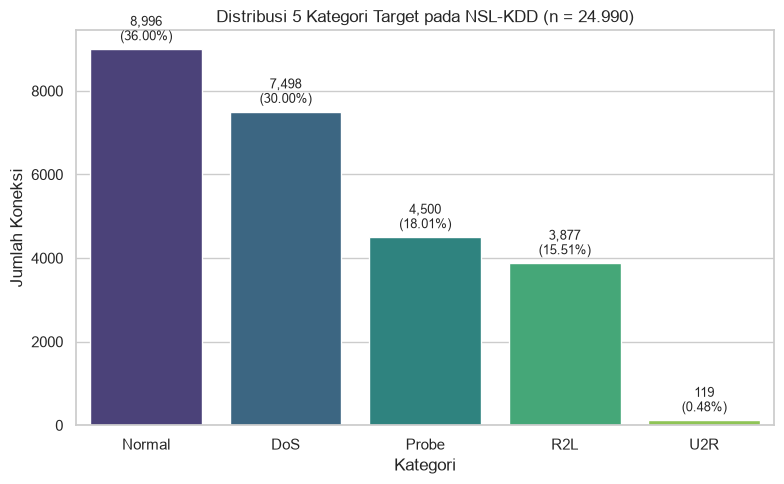

Insight 1 — Distribusi Kategori: Kelas Normal (8.996; 36,00%) dan DoS (7.498; 30,00%) mendominasi dataset, diikuti Probe (4.500; 18,01%) dan R2L (3.877; 15,51%). Sebaliknya, U2R hanya berjumlah 119 baris (0,48%), sehingga sangat rentan terhadap ketidakseimbangan kelas.
--------------------------------------------------------------------------------


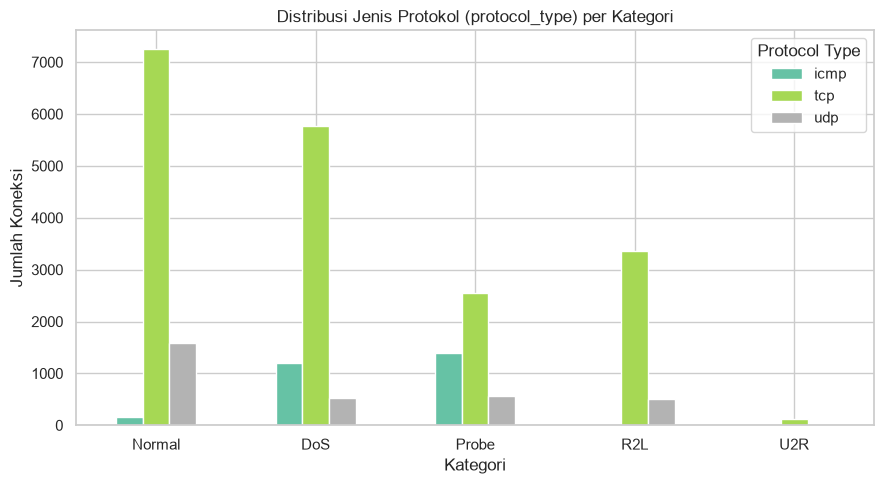

Tabel silang protocol_type per kategori:
protocol_type  icmp   tcp   udp
kategori                       
Normal          161  7248  1587
DoS            1201  5768   529
Probe          1389  2556   555
R2L               4  3362   511
U2R               0   116     3

Insight 2 — Protokol per Kategori: Protokol TCP mendominasi hampir seluruh kategori (termasuk hampir seluruh koneksi R2L dan U2R), sedangkan ICMP banyak muncul pada DoS dan Probe, dan UDP tersebar pada Normal, DoS, serta Probe.


In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

# Buat folder penyimpanan grafik EDA jika belum ada
eda_dir = PROJECT_ROOT / "results" / "eda"
eda_dir.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")

# --- GRAFIK 1: Distribusi Kategori ---
fig, ax = plt.subplots(figsize=(8, 5))
counts_kat = df[target_col].value_counts().reindex(urutan_kelas)
sns.barplot(x=counts_kat.index, y=counts_kat.values, palette="viridis", ax=ax)
ax.set_title("Distribusi 5 Kategori Target pada NSL-KDD (n = 24.990)")
ax.set_xlabel("Kategori")
ax.set_ylabel("Jumlah Koneksi")
for i, v in enumerate(counts_kat.values):
    pct = v / len(df) * 100
    ax.text(i, v + 120, f"{v:,}\n({pct:.2f}%)", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.savefig(eda_dir / "01_distribusi_kategori.png", dpi=150)
plt.show()

insight_1 = (
    "Insight 1 — Distribusi Kategori: Kelas Normal (8.996; 36,00%) dan DoS (7.498; 30,00%) "
    "mendominasi dataset, diikuti Probe (4.500; 18,01%) dan R2L (3.877; 15,51%). Sebaliknya, "
    "U2R hanya berjumlah 119 baris (0,48%), sehingga sangat rentan terhadap ketidakseimbangan kelas."
)
print(insight_1)
print("-" * 80)

# --- GRAFIK 2: Distribusi Protokol per Kategori ---
fig, ax = plt.subplots(figsize=(9, 5))
ct_proto = pd.crosstab(df[target_col], df["protocol_type"]).reindex(urutan_kelas)
ct_proto.plot(kind="bar", ax=ax, colormap="Set2")
ax.set_title("Distribusi Jenis Protokol (protocol_type) per Kategori")
ax.set_xlabel("Kategori")
ax.set_ylabel("Jumlah Koneksi")
ax.legend(title="Protocol Type")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(eda_dir / "02_protokol_per_kategori.png", dpi=150)
plt.show()

print("Tabel silang protocol_type per kategori:")
print(ct_proto)
insight_2 = (
    "Insight 2 — Protokol per Kategori: Protokol TCP mendominasi hampir seluruh kategori "
    "(termasuk hampir seluruh koneksi R2L dan U2R), sedangkan ICMP banyak muncul pada DoS dan Probe, "
    "dan UDP tersebar pada Normal, DoS, serta Probe."
)
print("\n" + insight_2)

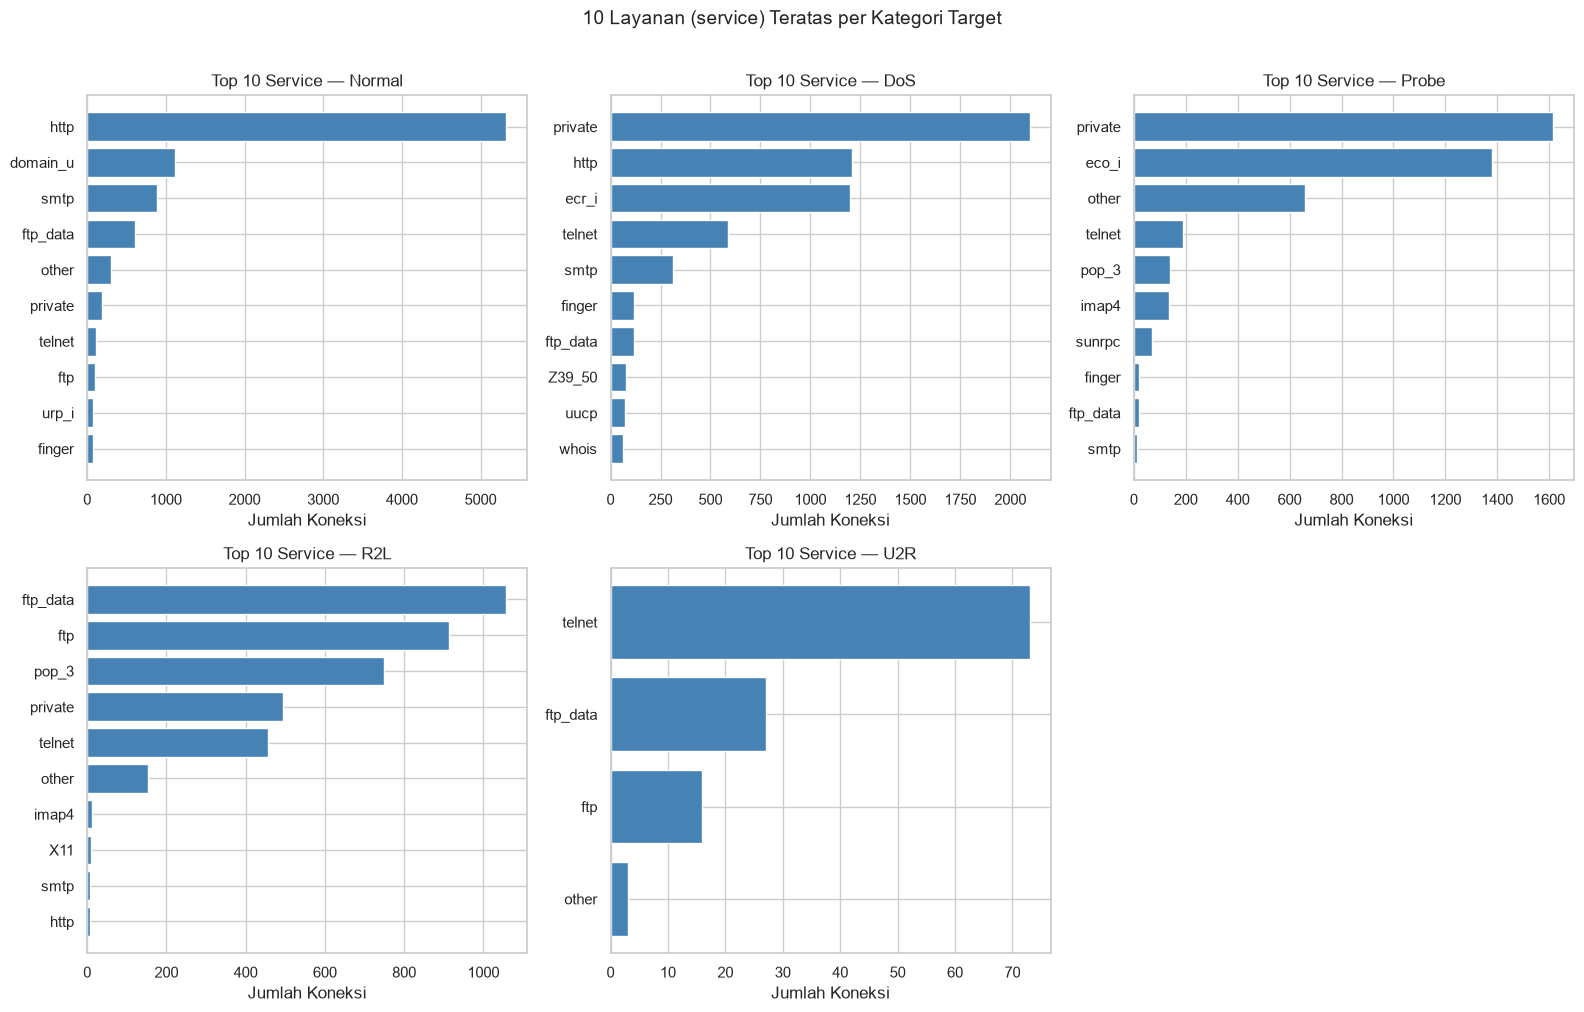

Insight 3 — Layanan Teratas per Kategori: Pola layanan sangat berbeda antar kategori, seperti dominasi layanan umum (misalnya http dan domain_u) pada Normal, layanan khusus pada DoS/Probe, serta layanan akses jarak jauh/login pada R2L dan U2R.
--------------------------------------------------------------------------------


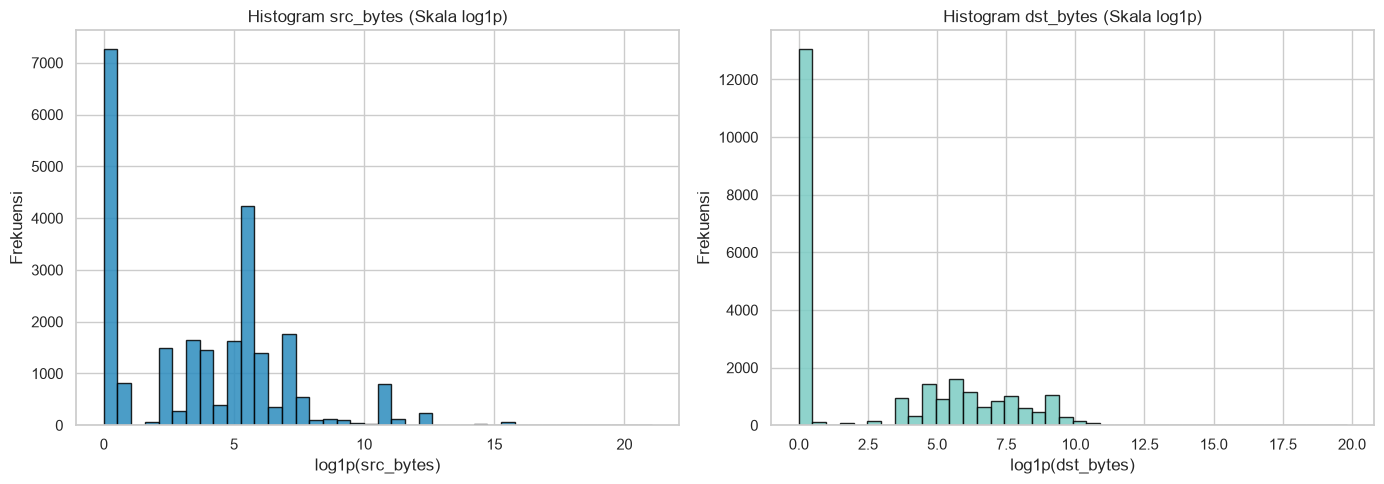


Insight 4 — Distribusi src_bytes & dst_bytes (Skala Log): Kedua fitur memiliki sebaran yang sangat miring ke kanan (right-skewed) dengan banyak nilai 0 serta lonjakan nilai besar; transformasi logaritmik membantu meratakan rentang ekstrem sebelum pemodelan.


In [15]:
# --- GRAFIK 3: 10 Layanan Teratas per Kategori ---
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for idx, kat in enumerate(urutan_kelas):
    ax = axes[idx]
    top10_srv = (
        df[df[target_col] == kat]["service"]
        .value_counts()
        .head(10)
        .sort_values(ascending=True)
    )
    ax.barh(top10_srv.index, top10_srv.values, color="steelblue")
    ax.set_title(f"Top 10 Service — {kat}")
    ax.set_xlabel("Jumlah Koneksi")

# Sembunyikan subplot ke-6 yang kosong
axes[-1].axis("off")

plt.suptitle("10 Layanan (service) Teratas per Kategori Target", fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig(eda_dir / "03_top10_service_per_kategori.png", dpi=150, bbox_inches="tight")
plt.show()

insight_3 = (
    "Insight 3 — Layanan Teratas per Kategori: Pola layanan sangat berbeda antar kategori, "
    "seperti dominasi layanan umum (misalnya http dan domain_u) pada Normal, layanan khusus pada DoS/Probe, "
    "serta layanan akses jarak jauh/login pada R2L dan U2R."
)
print(insight_3)
print("-" * 80)

# --- GRAFIK 4: Histogram src_bytes dan dst_bytes (Skala Log) ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Pakai np.log1p agar nilai 0 tetap aman dan mudah dibaca
log_src = np.log1p(df["src_bytes"])
log_dst = np.log1p(df["dst_bytes"])

axes[0].hist(log_src, bins=40, color="#2b8cbe", edgecolor="black", alpha=0.85)
axes[0].set_title("Histogram src_bytes (Skala log1p)")
axes[0].set_xlabel("log1p(src_bytes)")
axes[0].set_ylabel("Frekuensi")

axes[1].hist(log_dst, bins=40, color="#7bccc4", edgecolor="black", alpha=0.85)
axes[1].set_title("Histogram dst_bytes (Skala log1p)")
axes[1].set_xlabel("log1p(dst_bytes)")
axes[1].set_ylabel("Frekuensi")

plt.tight_layout()
plt.savefig(eda_dir / "04_histogram_log_src_dst_bytes.png", dpi=150)
plt.show()

insight_4 = (
    "Insight 4 — Distribusi src_bytes & dst_bytes (Skala Log): Kedua fitur memiliki sebaran "
    "yang sangat miring ke kanan (right-skewed) dengan banyak nilai 0 serta lonjakan nilai besar; "
    "transformasi logaritmik membantu meratakan rentang ekstrem sebelum pemodelan."
)
print("\n" + insight_4)

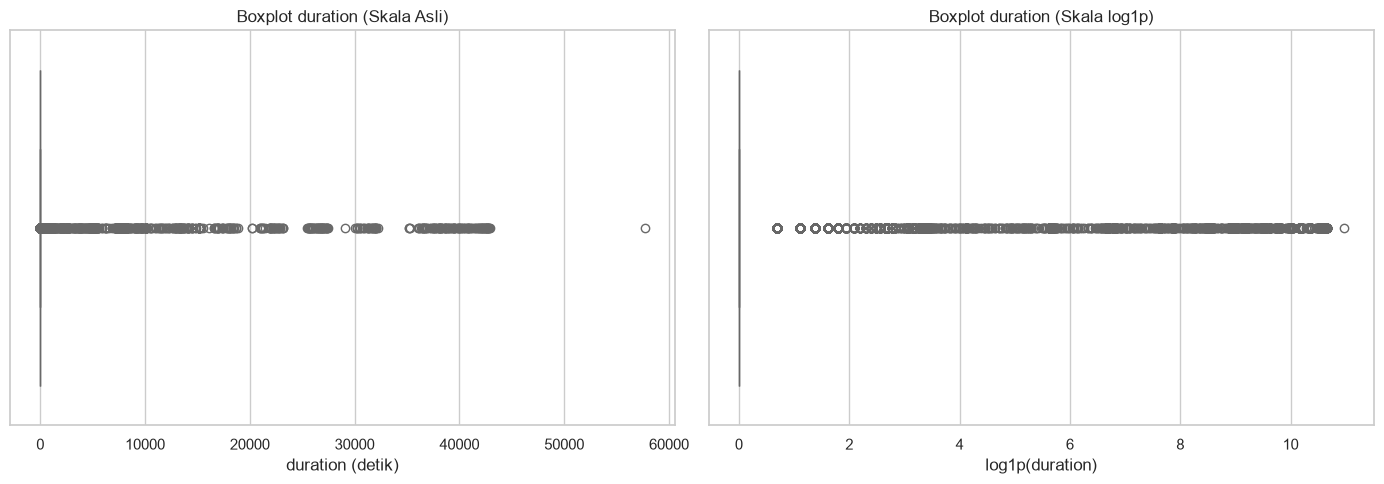

Insight 5 — Boxplot duration: Sebagian besar koneksi memiliki durasi sangat singkat atau 0 detik, namun terdapat pencilan (outlier) berdurasi panjang hingga puluhan ribu detik; skala log1p membantu melihat variasi durasi di luar pencilan ekstrem.
--------------------------------------------------------------------------------


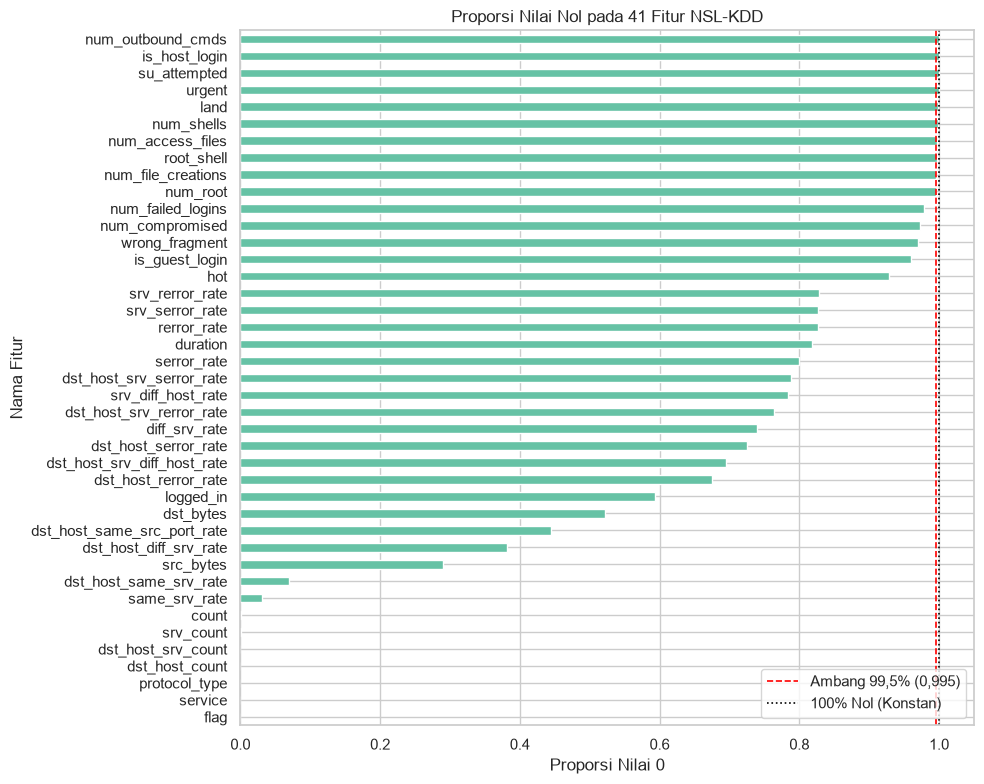

Top 12 fitur dengan proporsi nol tertinggi:
num_outbound_cmds     1.000000
is_host_login         0.999560
su_attempted          0.999520
urgent                0.999480
land                  0.999080
num_shells            0.998719
num_access_files      0.996919
root_shell            0.996439
num_file_creations    0.996158
num_root              0.994918
num_failed_logins     0.978551
num_compromised       0.972389
dtype: float64

Insight 6 — Proporsi Nol per Kolom: Fitur num_outbound_cmds 100% bernilai nol (konstan), dan beberapa fitur lain memiliki proporsi nol di atas 99,5% (seperti is_host_login, su_attempted, urgent, land, num_shells, num_access_files, root_shell, dan num_file_creations), sehingga perlu diuji dampaknya sebelum dibuang.


In [16]:
# --- GRAFIK 5: Boxplot duration ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Kiri: skala asli (terlihat efek outlier ekstrem)
sns.boxplot(x=df["duration"], color="#fc8d62", ax=axes[0])
axes[0].set_title("Boxplot duration (Skala Asli)")
axes[0].set_xlabel("duration (detik)")

# Kanan: skala log1p agar sebaran lebih mudah terbaca
sns.boxplot(x=np.log1p(df["duration"]), color="#8da0cb", ax=axes[1])
axes[1].set_title("Boxplot duration (Skala log1p)")
axes[1].set_xlabel("log1p(duration)")

plt.tight_layout()
plt.savefig(eda_dir / "05_boxplot_duration.png", dpi=150)
plt.show()

insight_5 = (
    "Insight 5 — Boxplot duration: Sebagian besar koneksi memiliki durasi sangat singkat atau 0 detik, "
    "namun terdapat pencilan (outlier) berdurasi panjang hingga puluhan ribu detik; skala log1p membantu "
    "melihat variasi durasi di luar pencilan ekstrem."
)
print(insight_5)
print("-" * 80)

# --- GRAFIK 6: Proporsi Nol per Kolom ---
zero_prop = (df[features] == 0).mean().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 8))
zero_prop.sort_values(ascending=True).plot(kind="barh", color="#66c2a5", ax=ax)
ax.axvline(0.995, color="red", linestyle="--", linewidth=1.2, label="Ambang 99,5% (0,995)")
ax.axvline(1.0, color="black", linestyle=":", linewidth=1.2, label="100% Nol (Konstan)")
ax.set_title("Proporsi Nilai Nol pada 41 Fitur NSL-KDD")
ax.set_xlabel("Proporsi Nilai 0")
ax.set_ylabel("Nama Fitur")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(eda_dir / "06_proporsi_nol_per_kolom.png", dpi=150)
plt.show()

print("Top 12 fitur dengan proporsi nol tertinggi:")
print(zero_prop.head(12))

insight_6 = (
    "Insight 6 — Proporsi Nol per Kolom: Fitur num_outbound_cmds 100% bernilai nol (konstan), dan "
    "beberapa fitur lain memiliki proporsi nol di atas 99,5% (seperti is_host_login, su_attempted, urgent, "
    "land, num_shells, num_access_files, root_shell, dan num_file_creations), sehingga perlu diuji dampaknya "
    "sebelum dibuang."
)
print("\n" + insight_6)

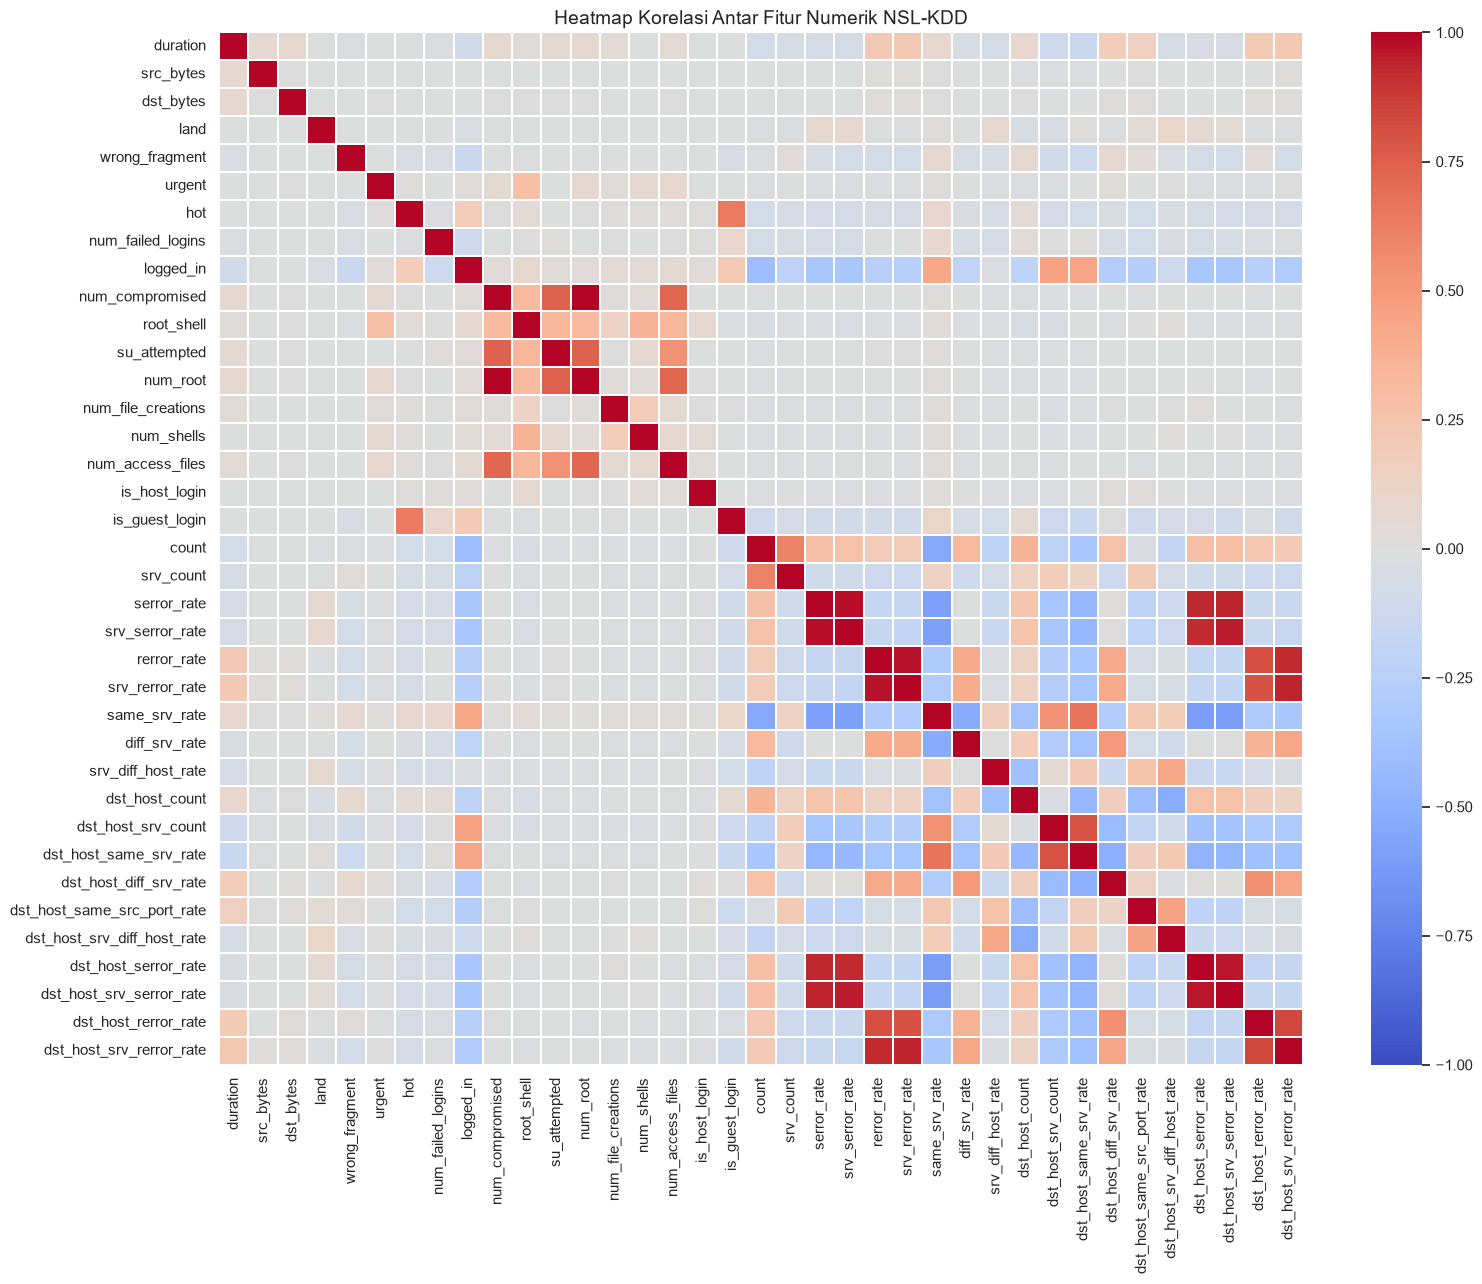

Pasangan fitur dengan korelasi sangat tinggi (|r| > 0.90):
             Fitur_1                  Fitur_2  Korelasi  Abs_Korelasi
     num_compromised                 num_root  0.996816      0.996816
         serror_rate          srv_serror_rate  0.979227      0.979227
         rerror_rate          srv_rerror_rate  0.975000      0.975000
dst_host_serror_rate dst_host_srv_serror_rate  0.964089      0.964089
     srv_serror_rate dst_host_srv_serror_rate  0.955398      0.955398
         serror_rate dst_host_srv_serror_rate  0.941425      0.941425
     srv_rerror_rate dst_host_srv_rerror_rate  0.941092      0.941092
         serror_rate     dst_host_serror_rate  0.934856      0.934856
         rerror_rate dst_host_srv_rerror_rate  0.925900      0.925900
     srv_serror_rate     dst_host_serror_rate  0.925653      0.925653

Insight 7 — Heatmap Korelasi Numerik: Terlihat beberapa kelompok fitur yang berkorelasi sangat kuat (|r| > 0,90), terutama kelompok rasio error SYN (serror_rate, srv_serr

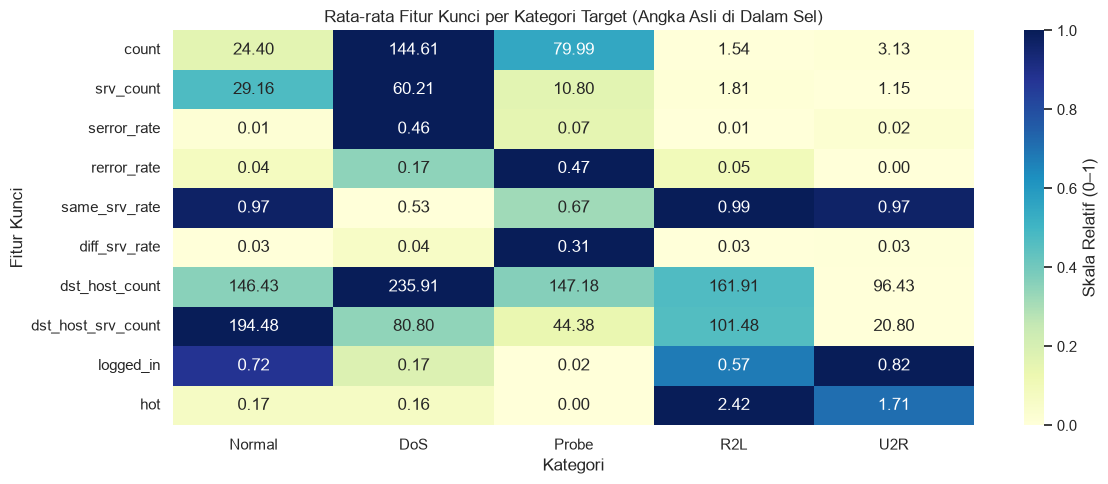


Insight 8 — Rata-rata Fitur Kunci per Kategori: Setiap kategori memiliki ciri numerik yang khas—DoS menonjol pada tingginya count dan serror_rate, Probe tinggi pada rerror_rate dan diff_srv_rate, sedangkan R2L dan U2R cenderung memiliki logged_in serta hot yang lebih tinggi dibanding serangan banjir paket.


In [18]:
# --- GRAFIK 7: Heatmap Korelasi Fitur Numerik ---
# Kecualikan num_outbound_cmds sementara saat hitung korelasi agar tidak menghasilkan baris/kolom NaN
num_for_corr = [c for c in numerical_cols if c != "num_outbound_cmds"]
corr_matrix = df[num_for_corr].corr()

fig, ax = plt.subplots(figsize=(16, 13))
sns.heatmap(corr_matrix, cmap="coolwarm", center=0, vmin=-1, vmax=1, linewidths=0.2, ax=ax)
ax.set_title("Heatmap Korelasi Antar Fitur Numerik NSL-KDD", fontsize=14)
plt.tight_layout()
plt.savefig(eda_dir / "07_heatmap_korelasi_numerik.png", dpi=150)
plt.show()

# Cari pasangan fitur dengan korelasi absolut tertinggi (> 0.90)
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
high_corr_pairs = (
    upper_tri.stack()
    .reset_index()
    .rename(columns={"level_0": "Fitur_1", "level_1": "Fitur_2", 0: "Korelasi"})
)
high_corr_pairs["Abs_Korelasi"] = high_corr_pairs["Korelasi"].abs()
high_corr_pairs = high_corr_pairs.sort_values("Abs_Korelasi", ascending=False)

print("Pasangan fitur dengan korelasi sangat tinggi (|r| > 0.90):")
print(high_corr_pairs[high_corr_pairs["Abs_Korelasi"] > 0.90].to_string(index=False))

insight_7 = (
    "Insight 7 — Heatmap Korelasi Numerik: Terlihat beberapa kelompok fitur yang berkorelasi sangat kuat "
    "(|r| > 0,90), terutama kelompok rasio error SYN (serror_rate, srv_serror_rate, dst_host_serror_rate, "
    "dst_host_srv_serror_rate) serta kelompok rasio error REJ (rerror_rate, srv_rerror_rate, "
    "dst_host_rerror_rate, dst_host_srv_rerror_rate), yang menandakan adanya redundansi informasi."
)
print("\n" + insight_7)
print("-" * 80)

# --- GRAFIK 8: Rata-rata Fitur Kunci per Kategori ---
fitur_kunci = [
    "count",
    "srv_count",
    "serror_rate",
    "rerror_rate",
    "same_srv_rate",
    "diff_srv_rate",
    "dst_host_count",
    "dst_host_srv_count",
    "logged_in",
    "hot",
]

mean_per_kat = df.groupby(target_col)[fitur_kunci].mean().reindex(urutan_kelas)

# Normalisasi min-max per kolom khusus visualisasi heatmap agar perbedaan antar kategori terbaca jelas
mean_norm = (mean_per_kat - mean_per_kat.min()) / (mean_per_kat.max() - mean_per_kat.min())

fig, ax = plt.subplots(figsize=(12, 5))
sns.heatmap(
    mean_norm.T,
    annot=mean_per_kat.T.round(2),
    fmt=".2f",
    cmap="YlGnBu",
    cbar_kws={"label": "Skala Relatif (0–1)"},
    ax=ax,
)
ax.set_title("Rata-rata Fitur Kunci per Kategori Target (Angka Asli di Dalam Sel)")
ax.set_xlabel("Kategori")
ax.set_ylabel("Fitur Kunci")
plt.tight_layout()
plt.savefig(eda_dir / "08_rata_rata_fitur_kunci_per_kategori.png", dpi=150)
plt.show()

insight_8 = (
    "Insight 8 — Rata-rata Fitur Kunci per Kategori: Setiap kategori memiliki ciri numerik yang khas—"
    "DoS menonjol pada tingginya count dan serror_rate, Probe tinggi pada rerror_rate dan diff_srv_rate, "
    "sedangkan R2L dan U2R cenderung memiliki logged_in serta hot yang lebih tinggi dibanding serangan banjir paket."
)
print("\n" + insight_8)

In [19]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import make_scorer, recall_score

# Siapkan X dan y awal (41 fitur)
X_full = df[features].copy()
y_full = df[target_col].copy()

# 1. Identifikasi kolom konstan & proporsi nol > 99.5%
zero_props = (X_full == 0).mean()
cols_zero_gt_995 = zero_props[zero_props > 0.995].index.tolist()
print("Kolom dengan proporsi nol > 0.995 (termasuk num_outbound_cmds):", cols_zero_gt_995)

# 2. Kandidat kolom redundan dari korelasi sangat tinggi (|r| > 0.95)
# num_root sangat berkorelasi dengan num_compromised (0.997)
# srv_serror_rate, dst_host_srv_serror_rate, srv_rerror_rate, dst_host_srv_rerror_rate sangat berkorelasi dengan induknya
cols_high_corr_drop = [
    "num_root",
    "srv_serror_rate",
    "dst_host_srv_serror_rate",
    "srv_rerror_rate",
    "dst_host_srv_rerror_rate",
]

# Susun daftar kolom yang akan dibuang (gabungan unik)
cols_to_drop = list(dict.fromkeys(cols_zero_gt_995 + cols_high_corr_drop))
print("Total fitur yang dibuang:", len(cols_to_drop))
print("Daftar fitur yang dibuang:", cols_to_drop)

# Susun tabel alasan pembuangan tiap variabel
alasan_list = []
for col in cols_to_drop:
    prop_0 = float((X_full[col] == 0).mean())
    if col == "num_outbound_cmds":
        alasan = "Konstan (100% bernilai 0 pada seluruh data), tidak memberikan informasi pembeda."
    elif col in cols_zero_gt_995:
        alasan = f"Proporsi nilai nol sangat tinggi ({prop_0:.2%} > 99,5%), varians nyaris nol."
    else:
        alasan = "Korelasi sangat tinggi (redundan) dengan fitur sejenis yang dipertahankan."
    alasan_list.append({
        "nama_kolom": col,
        "proporsi_nol": round(prop_0, 6),
        "alasan_dibuang": alasan
    })

tabel_dibuang = pd.DataFrame(alasan_list)
tabel_dibuang.to_csv(PROJECT_ROOT / "results" / "tabel_variabel_dibuang.csv", index=False)
print("\nTabel variabel yang dibuang:")
print(tabel_dibuang.to_string(index=False))

# Fungsi bantu evaluasi 5-fold CV untuk macro_f1, recall_R2L, recall_U2R
def evaluasi_subset_fitur(kolom_fitur, label_eksperimen):
    cat_sub = [c for c in categorical_cols if c in kolom_fitur]
    log_cols = [c for c in ["duration", "src_bytes", "dst_bytes"] if c in kolom_fitur]
    num_sub = [c for c in kolom_fitur if c not in cat_sub and c not in log_cols]

    pre = ColumnTransformer(
        transformers=[
            ("cat", OneHotEncoder(handle_unknown="ignore"), cat_sub),
            ("log", FunctionTransformer(np.log1p, validate=False), log_cols),
            ("num", "passthrough", num_sub),
        ],
        remainder="drop",
    )

    clf = Pipeline([
        ("prep", pre),
        ("model", DecisionTreeClassifier(random_state=random_state)),
    ])

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=random_state)
    scoring = {
        "macro_f1": "f1_macro",
        "recall_R2L": make_scorer(recall_score, labels=["R2L"], average="macro", zero_division=0),
        "recall_U2R": make_scorer(recall_score, labels=["U2R"], average="macro", zero_division=0),
    }

    res = cross_validate(clf, X_full[kolom_fitur], y_full, cv=cv, scoring=scoring, n_jobs=-1)
    return {
        "Skenario": label_eksperimen,
        "Jumlah_Fitur": len(kolom_fitur),
        "Macro_F1_Mean": round(res["test_macro_f1"].mean(), 4),
        "Recall_R2L_Mean": round(res["test_recall_R2L"].mean(), 4),
        "Recall_U2R_Mean": round(res["test_recall_U2R"].mean(), 4),
    }

fitur_tanpa_zero995 = [c for c in features if c not in cols_zero_gt_995]
fitur_seleksi_akhir = [c for c in features if c not in cols_to_drop]

hasil_seleksi = pd.DataFrame([
    evaluasi_subset_fitur(features, "1. Semua 41 Fitur (Baseline)"),
    evaluasi_subset_fitur(fitur_tanpa_zero995, "2. Hapus Nol > 99,5% & Konstan"),
    evaluasi_subset_fitur(fitur_seleksi_akhir, "3. Hapus Nol > 99,5% + Korelasi Tinggi"),
])

print("\nPerbandingan skor 5-fold CV (Macro-F1, Recall R2L, Recall U2R):")
print(hasil_seleksi.to_string(index=False))

insight_seleksi = (
    "Insight Seleksi Variabel: Pembuangan fitur konstan/hampir nol (>99,5%) dan fitur redundan "
    "berkorelasi sangat tinggi menjaga stabilitas Macro-F1 serta recall kelas serangan (R2L dan U2R) "
    "sambil mengurangi kompleksitas dimensi input."
)
print("\n" + insight_seleksi)

Kolom dengan proporsi nol > 0.995 (termasuk num_outbound_cmds): ['land', 'urgent', 'root_shell', 'su_attempted', 'num_file_creations', 'num_shells', 'num_access_files', 'num_outbound_cmds', 'is_host_login']
Total fitur yang dibuang: 14
Daftar fitur yang dibuang: ['land', 'urgent', 'root_shell', 'su_attempted', 'num_file_creations', 'num_shells', 'num_access_files', 'num_outbound_cmds', 'is_host_login', 'num_root', 'srv_serror_rate', 'dst_host_srv_serror_rate', 'srv_rerror_rate', 'dst_host_srv_rerror_rate']

Tabel variabel yang dibuang:
              nama_kolom  proporsi_nol                                                                   alasan_dibuang
                    land      0.999080           Proporsi nilai nol sangat tinggi (99.91% > 99,5%), varians nyaris nol.
                  urgent      0.999480           Proporsi nilai nol sangat tinggi (99.95% > 99,5%), varians nyaris nol.
              root_shell      0.996439           Proporsi nilai nol sangat tinggi (99.64% > 99,5%)

In [21]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Tentukan fitur final setelah seleksi variabel
selected_features = [c for c in features if c not in cols_to_drop]
print("Jumlah fitur final:", len(selected_features))

X = df[selected_features].copy()
y = df[target_col].copy()

# 2. Split 80/20 berstrata (random_state=42) dan bekukan
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=random_state,
)

processed_dir = PROJECT_ROOT / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

# Simpan split agar bisa dipakai bersama (termasuk A3)
train_df = X_train.copy()
train_df[target_col] = y_train
test_df = X_test.copy()
test_df[target_col] = y_test

train_df.to_csv(processed_dir / "train_split_80_20.csv", index=False)
test_df.to_csv(processed_dir / "test_split_80_20.csv", index=False)

# Simpan juga daftar fitur final & metadata split
split_meta = {
    "random_state": random_state,
    "test_size": 0.20,
    "stratified": True,
    "urutan_kelas": urutan_kelas,
    "selected_features": selected_features,
    "dropped_features": cols_to_drop,
    "n_train": int(len(X_train)),
    "n_test": int(len(X_test)),
}
with open(processed_dir / "split_config.json", "w", encoding="utf-8") as f:
    json.dump(split_meta, f, indent=2)

print("Ukuran X_train:", X_train.shape, "| Ukuran X_test:", X_test.shape)
print("\nDistribusi y_train:")
print(y_train.value_counts().reindex(urutan_kelas))
print("\nDistribusi y_test:")
print(y_test.value_counts().reindex(urutan_kelas))

# 3. Bangun Pre-processing ColumnTransformer (khusus SVM & MLP: pakai StandardScaler)
cat_cols_final = [c for c in categorical_cols if c in selected_features]
log_cols_final = [c for c in ["duration", "src_bytes", "dst_bytes"] if c in selected_features]
num_cols_final = [
    c for c in selected_features
    if c not in cat_cols_final and c not in log_cols_final
]

preprocessor_scaled = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols_final),
        (
            "log_scaled",
            Pipeline([
                ("log1p", FunctionTransformer(np.log1p, validate=False)),
                ("scaler", StandardScaler()),
            ]),
            log_cols_final,
        ),
        ("num_scaled", StandardScaler(), num_cols_final),
    ],
    remainder="drop",
)

# Uji fit HANYA pada X_train lalu transform X_train dan X_test (anti kebocoran data)
X_train_proc = preprocessor_scaled.fit_transform(X_train)
X_test_proc = preprocessor_scaled.transform(X_test)

print("\nShape setelah pre-processing (fit di train saja):")
print("X_train_proc:", X_train_proc.shape, "| X_test_proc:", X_test_proc.shape)

Jumlah fitur final: 27
Ukuran X_train: (19992, 27) | Ukuran X_test: (4998, 27)

Distribusi y_train:
kategori
Normal    7197
DoS       5998
Probe     3600
R2L       3102
U2R         95
Name: count, dtype: int64

Distribusi y_test:
kategori
Normal    1799
DoS       1500
Probe      900
R2L        775
U2R         24
Name: count, dtype: int64

Shape setelah pre-processing (fit di train saja):
X_train_proc: (19992, 106) | X_test_proc: (4998, 106)


Fitting 5 folds for each of 6 candidates, totalling 30 fits


c:\Users\user\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Parameter terbaik SVM (RBF): {'clf__gamma': 0.05, 'clf__C': 25.0}
Skor 5-fold CV macro-F1 terbaik SVM: 0.9329 (waktu: 140.36s)


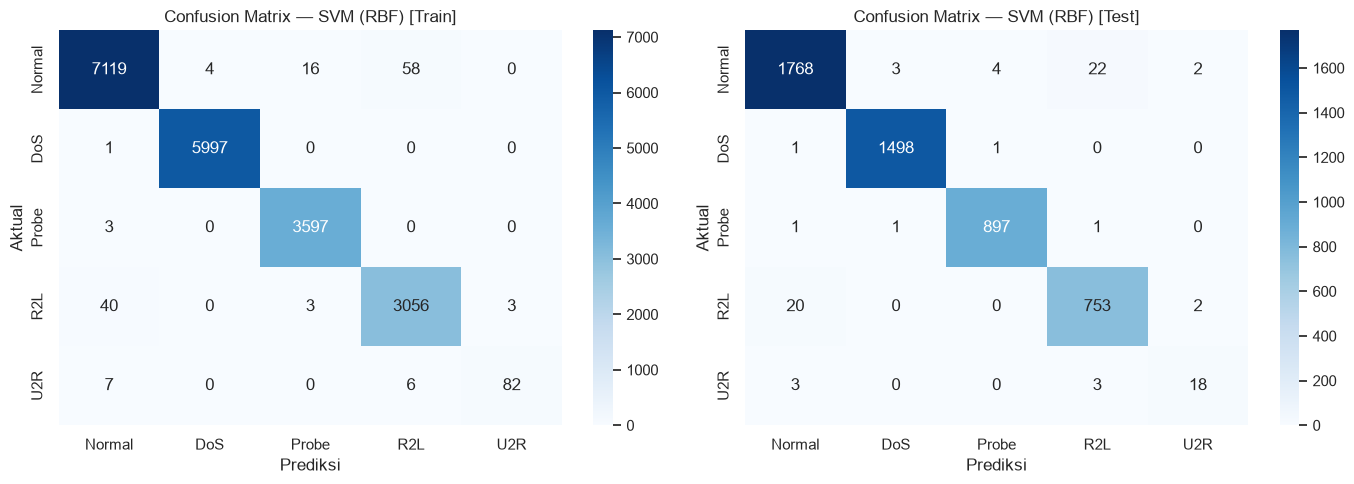


Classification Report SVM (RBF) — Test:
              precision    recall  f1-score   support

      Normal     0.9861    0.9828    0.9844      1799
         DoS     0.9973    0.9987    0.9980      1500
       Probe     0.9945    0.9967    0.9956       900
         R2L     0.9666    0.9716    0.9691       775
         U2R     0.8182    0.7500    0.7826        24

    accuracy                         0.9872      4998
   macro avg     0.9525    0.9399    0.9459      4998
weighted avg     0.9871    0.9872    0.9872      4998



In [22]:
import time
import joblib
from sklearn.svm import SVC
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

models_dir = PROJECT_ROOT / "models"
results_dir = PROJECT_ROOT / "results"
models_dir.mkdir(parents=True, exist_ok=True)
results_dir.mkdir(parents=True, exist_ok=True)

# 1. Susun Pipeline penuh (Pre-processing + SVM RBF)
svm_pipe = Pipeline([
    ("prep", preprocessor_scaled),
    ("clf", SVC(kernel="rbf", probability=True, random_state=random_state)),
])

# 2. Tuning terbatas C dan gamma dengan 5-fold Stratified CV (metrik macro_f1)
cv_5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=random_state)
param_dist_svm = {
    "clf__C": [0.5, 1.0, 5.0, 10.0, 25.0],
    "clf__gamma": ["scale", "auto", 0.01, 0.05, 0.1],
}

search_svm = RandomizedSearchCV(
    estimator=svm_pipe,
    param_distributions=param_dist_svm,
    n_iter=6,  # tuning terbatas agar waktu komputasi tetap masuk akal
    scoring="f1_macro",
    cv=cv_5,
    random_state=random_state,
    n_jobs=-1,
    verbose=1,
)

t0 = time.time()
search_svm.fit(X_train, y_train)
train_time_svm = round(time.time() - t0, 4)

best_svm = search_svm.best_estimator_
best_cv_macro_f1_svm = float(search_svm.best_score_)

print("Parameter terbaik SVM (RBF):", search_svm.best_params_)
print(f"Skor 5-fold CV macro-F1 terbaik SVM: {best_cv_macro_f1_svm:.4f} (waktu: {train_time_svm:.2f}s)")

# 3. Prediksi train dan test
y_pred_train_svm = best_svm.predict(X_train)
y_pred_test_svm = best_svm.predict(X_test)

def bangun_blok_evaluasi(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=urutan_kelas)
    rep_dict = classification_report(
        y_true, y_pred, labels=urutan_kelas, output_dict=True, zero_division=0
    )
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_f1": float(f1_score(y_true, y_pred, labels=urutan_kelas, average="macro", zero_division=0)),
        "classification_report": rep_dict,
        "confusion_matrix": cm.tolist(),
    }, cm

train_block_svm, cm_train_svm = bangun_blok_evaluasi(y_train, y_pred_train_svm)
test_block_svm, cm_test_svm = bangun_blok_evaluasi(y_test, y_pred_test_svm)

# 4. Simpan model Pipeline (joblib, compress=3) & metrics JSON sesuai format panduan
joblib.dump(best_svm, models_dir / "svm_rbf.joblib", compress=3)

metrics_svm = {
    "model_name": "SVM (RBF)",
    "target": target_col,
    "classes": urutan_kelas,
    "best_params": search_svm.best_params_,
    "train": train_block_svm,
    "test": test_block_svm,
    "cv_macro_f1": best_cv_macro_f1_svm,
    "train_time_s": train_time_svm,
}

with open(results_dir / "metrics_svm_rbf.json", "w", encoding="utf-8") as f:
    json.dump(metrics_svm, f, indent=2)

# 5. Plot & simpan Confusion Matrix Train dan Test
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, cm, judul in [
    (axes[0], cm_train_svm, "Confusion Matrix — SVM (RBF) [Train]"),
    (axes[1], cm_test_svm, "Confusion Matrix — SVM (RBF) [Test]"),
]:
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=urutan_kelas,
        yticklabels=urutan_kelas,
        ax=ax,
    )
    ax.set_title(judul)
    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Aktual")

plt.tight_layout()
plt.savefig(results_dir / "cm_svm_rbf_train_test.png", dpi=150)
plt.show()

print("\nClassification Report SVM (RBF) — Test:")
print(classification_report(y_test, y_pred_test_svm, labels=urutan_kelas, digits=4, zero_division=0))

Fitting 5 folds for each of 6 candidates, totalling 30 fits
Parameter terbaik MLP: {'clf__hidden_layer_sizes': (128,), 'clf__alpha': 0.001}
Skor 5-fold CV macro-F1 terbaik MLP: 0.9238 (waktu: 48.41s)


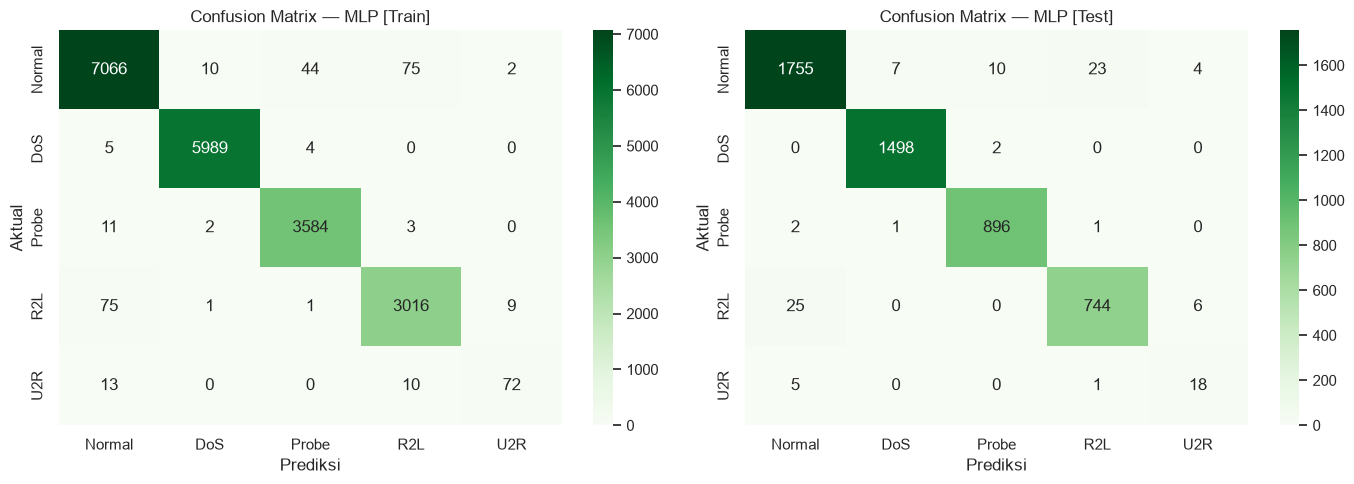


Classification Report MLP — Test:
              precision    recall  f1-score   support

      Normal     0.9821    0.9755    0.9788      1799
         DoS     0.9947    0.9987    0.9967      1500
       Probe     0.9868    0.9956    0.9912       900
         R2L     0.9675    0.9600    0.9637       775
         U2R     0.6429    0.7500    0.6923        24

    accuracy                         0.9826      4998
   macro avg     0.9148    0.9360    0.9245      4998
weighted avg     0.9828    0.9826    0.9827      4998



In [23]:
from sklearn.neural_network import MLPClassifier

mlp_pipe = Pipeline([
    ("prep", preprocessor_scaled),
    ("clf", MLPClassifier(max_iter=300, early_stopping=True, random_state=random_state)),
])

param_dist_mlp = {
    "clf__hidden_layer_sizes": [(64,), (128,), (128, 64), (64, 32)],
    "clf__alpha": [1e-4, 1e-3, 1e-2, 5e-2],
}

search_mlp = RandomizedSearchCV(
    estimator=mlp_pipe,
    param_distributions=param_dist_mlp,
    n_iter=6,
    scoring="f1_macro",
    cv=cv_5,
    random_state=random_state,
    n_jobs=-1,
    verbose=1,
)

t0 = time.time()
search_mlp.fit(X_train, y_train)
train_time_mlp = round(time.time() - t0, 4)

best_mlp = search_mlp.best_estimator_
best_cv_macro_f1_mlp = float(search_mlp.best_score_)

print("Parameter terbaik MLP:", search_mlp.best_params_)
print(f"Skor 5-fold CV macro-F1 terbaik MLP: {best_cv_macro_f1_mlp:.4f} (waktu: {train_time_mlp:.2f}s)")

y_pred_train_mlp = best_mlp.predict(X_train)
y_pred_test_mlp = best_mlp.predict(X_test)

train_block_mlp, cm_train_mlp = bangun_blok_evaluasi(y_train, y_pred_train_mlp)
test_block_mlp, cm_test_mlp = bangun_blok_evaluasi(y_test, y_pred_test_mlp)

joblib.dump(best_mlp, models_dir / "mlp.joblib", compress=3)

metrics_mlp = {
    "model_name": "MLP",
    "target": target_col,
    "classes": urutan_kelas,
    "best_params": search_mlp.best_params_,
    "train": train_block_mlp,
    "test": test_block_mlp,
    "cv_macro_f1": best_cv_macro_f1_mlp,
    "train_time_s": train_time_mlp,
}

with open(results_dir / "metrics_mlp.json", "w", encoding="utf-8") as f:
    json.dump(metrics_mlp, f, indent=2)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, cm, judul in [
    (axes[0], cm_train_mlp, "Confusion Matrix — MLP [Train]"),
    (axes[1], cm_test_mlp, "Confusion Matrix — MLP [Test]"),
]:
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Greens",
        xticklabels=urutan_kelas,
        yticklabels=urutan_kelas,
        ax=ax,
    )
    ax.set_title(judul)
    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Aktual")

plt.tight_layout()
plt.savefig(results_dir / "cm_mlp_train_test.png", dpi=150)
plt.show()

print("\nClassification Report MLP — Test:")
print(classification_report(y_test, y_pred_test_mlp, labels=urutan_kelas, digits=4, zero_division=0))